# Used Car Price Prediction — PGDip project
This notebook follows a direct, step-by-step coding style: inspect the data, clean it, split it, explore it, prepare the inputs, train three models, compare them and save the selected pipeline for Streamlit.

**Environment:** Open this folder in VS Code and select your .venv as the notebook kernel. Read the explanations and saved outputs first. Running cells from the top retrains the models; the final saving cell overwrites car_price_pipeline.joblib. The supplied app can run without rerunning this notebook.

This is a revised academic project with AI-assisted corrections, not data-science employment experience. Study and explain the decisions in your own words. The original data source, licence, collection dates, currency and engine/power/fuel-economy units remain unconfirmed. The project is not validated for current South African vehicle prices.

## 1. Import the packages
These imports provide tables, calculations, plots and the modelling tools. No separate project scripts or custom classes are used.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

## 2. Load and inspect the data
Keep the CSV in the same folder as this notebook. These initial checks identify columns, data types and data-quality problems.

In [2]:
df = pd.read_csv('car_price_dataset.csv')
print('Rows and columns:', df.shape)
df.head()

Rows and columns: (15411, 14)
Out[0]: 
   Unnamed: 0       car_name    brand  ... max_power  seats  selling_price
0           0    Maruti Alto   Maruti  ...     46.30      5         120000
1           1  Hyundai Grand  Hyundai  ...     82.00      5         550000
2           2    Hyundai i20  Hyundai  ...     80.00      5         215000
3           3    Maruti Alto   Maruti  ...     67.10      5         226000
4           4  Ford Ecosport     Ford  ...     98.59      5         570000

[5 rows x 14 columns]


In [3]:
df.tail()

Out[0]: 
       Unnamed: 0         car_name     brand  ... max_power  seats  selling_price
15406       19537      Hyundai i10   Hyundai  ...     68.05      5         250000
15407       19540    Maruti Ertiga    Maruti  ...     91.10      7         925000
15408       19541      Skoda Rapid     Skoda  ...    103.52      5         425000
15409       19542  Mahindra XUV500  Mahindra  ...    140.00      7        1225000
15410       19543       Honda City     Honda  ...    117.60      5        1200000

[5 rows x 14 columns]


In [4]:
df.info()  # Shows data types and non-missing counts.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [5]:
df.describe()  # Numerical ranges and typical values.

Out[0]: 
         Unnamed: 0   vehicle_age  ...         seats  selling_price
count  15411.000000  15411.000000  ...  15411.000000   1.541100e+04
mean    9811.857699      6.036338  ...      5.325482   7.749711e+05
std     5643.418542      3.013291  ...      0.807628   8.941284e+05
min        0.000000      0.000000  ...      0.000000   4.000000e+04
25%     4906.500000      4.000000  ...      5.000000   3.850000e+05
50%     9872.000000      6.000000  ...      5.000000   5.560000e+05
75%    14668.500000      8.000000  ...      5.000000   8.250000e+05
max    19543.000000     29.000000  ...      9.000000   3.950000e+07

[8 rows x 8 columns]


In [6]:
df.isna().sum()  # Ordinary blanks are not the only possible data-quality issue.

Out[0]: 
Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64


In [7]:
df.nunique()  # Number of distinct values in each column.

Out[0]: 
Unnamed: 0           15411
car_name               121
brand                   32
model                  120
vehicle_age             24
km_driven             3688
seller_type              3
fuel_type                5
transmission_type        2
mileage                411
engine                 110
max_power              342
seats                    8
selling_price         1086
dtype: int64


**Initial observations:** there are 15,411 rows and 14 columns, with no ordinary blank cells. However, two seat values are zero, and the maximum distance is 3.8 million km. An exported row index is present. No listing date, vehicle identifier, location, condition or service history is available. Missing information limits what the model can learn.

## 3. Clean the data
First identify the inputs and target. Drop the exported index and combined name; brand and model are retained. A unique row index can hide otherwise duplicated records and should not be used to predict price.

In [8]:
numeric_columns = ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
category_columns = ['brand', 'model', 'seller_type', 'fuel_type', 'transmission_type']
feature_columns = numeric_columns + category_columns

# Select only the columns used in the analysis, in a fixed order.
df = df[feature_columns + ['selling_price']].copy()

Strip accidental spaces and treat blank strings as missing. Normalise the two Isuzu spellings. Keep other ambiguous model names unchanged unless the source confirms they mean the same thing.

In [9]:
for column in category_columns:
    df[column] = df[column].astype('string').str.strip().replace('', pd.NA)
    df[column] = df[column].astype(object).where(df[column].notna(), np.nan)

df['brand'] = df['brand'].replace({'ISUZU': 'Isuzu'})

Check that numerical values can be read as numbers. Invalid or missing targets cannot be used for supervised training. These fixed rules do not learn anything from test-set averages.

In [10]:
for column in numeric_columns + ['selling_price']:
    df[column] = pd.to_numeric(df[column], errors='coerce')

valid_price = np.isfinite(df['selling_price']) & (df['selling_price'] > 0)
print('Invalid target rows removed:', (~valid_price).sum())
df = df.loc[valid_price].copy()

Invalid target rows removed: 0


Mark invalid numerical specifications as missing. Zero kilometres or zero years can be valid; zero seats, engine size, power or fuel economy are not accepted. We will fill missing inputs using medians learned from training folds later.

In [11]:
for column in numeric_columns:
    invalid = ~np.isfinite(df[column]) | (df[column] < 0)
    if column in ['mileage', 'engine', 'max_power', 'seats']:
        invalid = invalid | (df[column] == 0)
    if column in ['vehicle_age', 'seats']:
        invalid = invalid | (df[column].notna() & (df[column] % 1 != 0))
    df.loc[invalid, column] = np.nan

df.isna().sum()

Out[0]: 
vehicle_age          0
km_driven            0
mileage              0
engine               0
max_power            0
seats                2
brand                0
model                0
seller_type          0
fuel_type            0
transmission_type    0
selling_price        0
dtype: int64


In [12]:
print('Exact duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print('Rows after cleaning:', len(df))

Exact duplicate rows: 167
Rows after cleaning: 15244


**Cleaning outcome:** 167 duplicates are removed, leaving 15,244 rows. Two zero-seat values become missing. No price rows are removed. Positive extremes are retained for investigation, not automatically deleted to improve scores. The assignment requests outlier removal; explain this deliberate choice to the assessor rather than claiming all flagged extremes are errors.

## 4. Separate development and test data
X contains the inputs; y contains the price to predict. Reserve about 20% for testing. This uses groups because rows with identical inputs can have different prices. They must stay together, otherwise the same input profile could appear in both sets. This cannot identify the same physical car if its recorded details differ.

The hash below gives identical input rows the same group number. GroupShuffleSplit selects groups, so the row split is approximately 80/20. The fixed random seed makes the split reproducible.

In [13]:
X = df[feature_columns]
y = df['selling_price']

groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_index, test_index = next(split.split(X, y, groups))

X_train = X.iloc[train_index].copy()
X_test = X.iloc[test_index].copy()
y_train = y.iloc[train_index].copy()
y_test = y.iloc[test_index].copy()
train_groups = groups[train_index]

print('Development rows:', len(X_train))
print('Test rows:', len(X_test))
assert set(train_groups).isdisjoint(set(groups[test_index]))

Development rows: 12163
Test rows: 3081


## 5. Explore the development data
Use development data for detailed exploration. Keep the test set out of model-design decisions. Histograms and box plots describe distributions; a box-plot flag does not prove a data error.

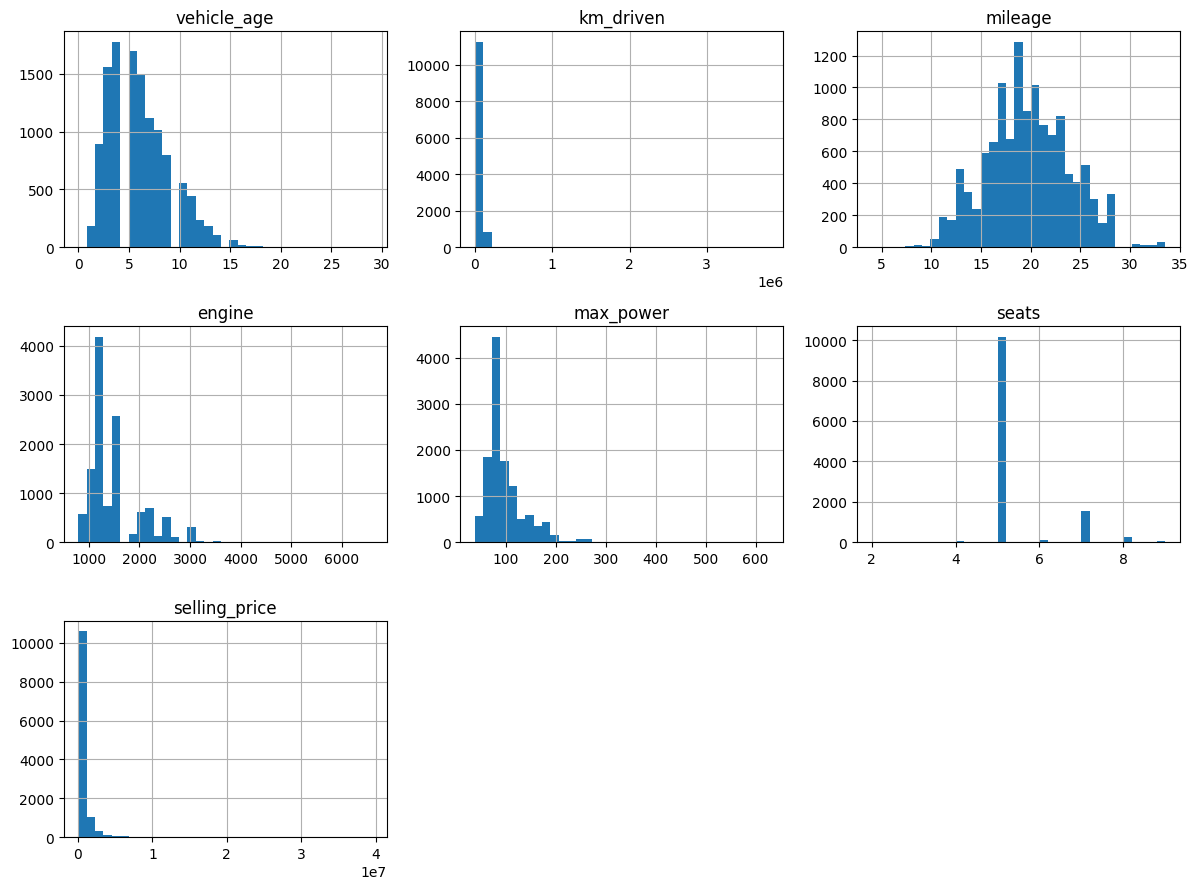

In [14]:
development = df.iloc[train_index].copy()
development[numeric_columns + ['selling_price']].hist(bins=35, figsize=(12, 9))
plt.tight_layout()
plt.show()

In [15]:
development[numeric_columns + ['selling_price']].skew().to_frame('Skewness')

Out[0]: 
                Skewness
vehicle_age     0.853578
km_driven      31.309677
mileage         0.124064
engine          1.662513
max_power       2.558680
seats           2.083339
selling_price  11.209705


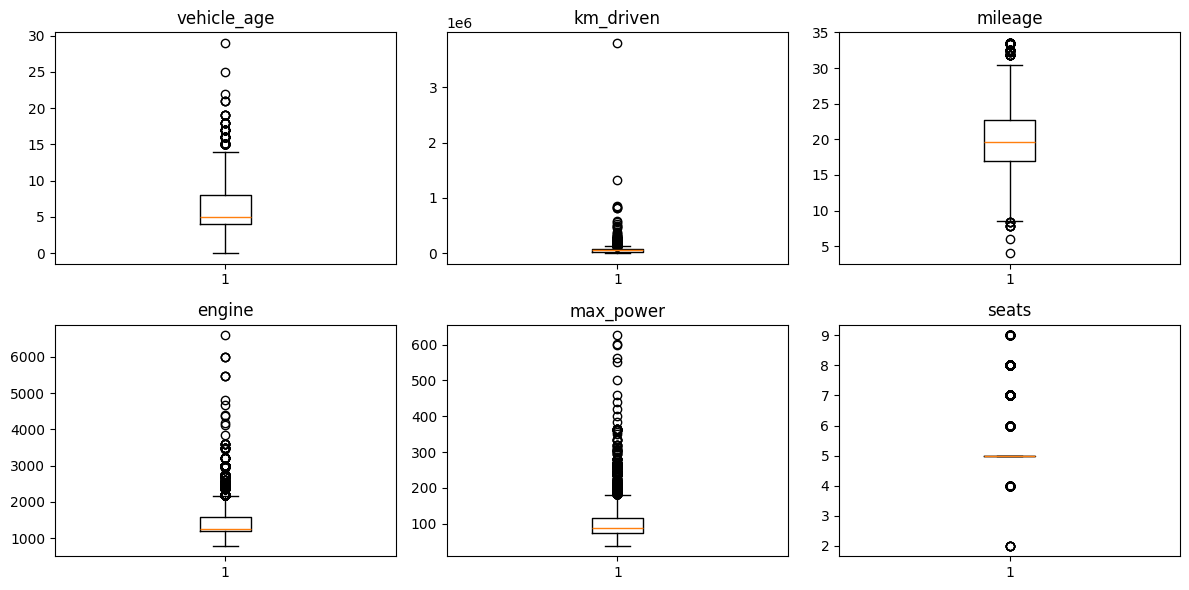

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for column, ax in zip(numeric_columns, axes.flat):
    ax.boxplot(development[column].dropna())
    ax.set_title(column)
plt.tight_layout()
plt.show()

In [17]:
# Count IQR outlier flags using development data only.
q1 = development[numeric_columns].quantile(0.25)
q3 = development[numeric_columns].quantile(0.75)
iqr = q3 - q1
flags = (development[numeric_columns] < q1 - 1.5 * iqr) | (development[numeric_columns] > q3 + 1.5 * iqr)
flags.sum().to_frame('Flagged for review')

Out[0]: 
             Flagged for review
vehicle_age                 118
km_driven                   361
mileage                      73
engine                     1672
max_power                   660
seats                      1985


Price is strongly skewed, so a log-price plot helps show its distribution. This plot does not alter y. Ridge will use one log1p target transformation; its predictions are automatically converted back with expm1. Trees will predict ordinary prices. Neither tree models nor every input distribution needs to be normal.

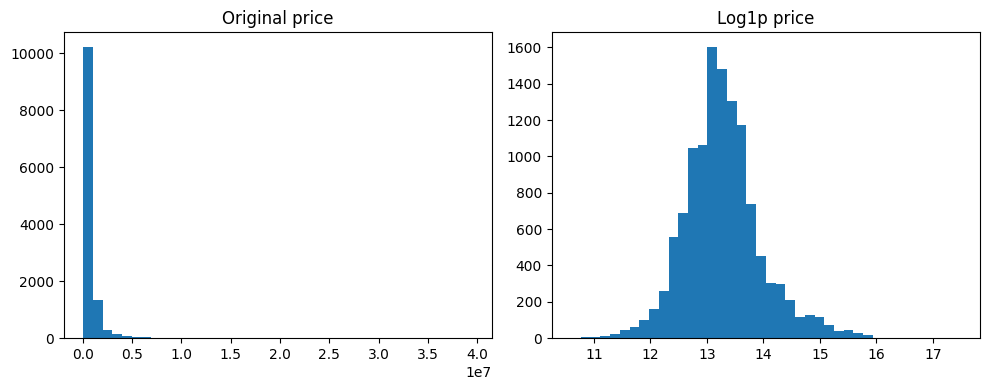

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y_train, bins=40)
axes[0].set_title('Original price')
axes[1].hist(np.log1p(y_train), bins=40)
axes[1].set_title('Log1p price')
plt.tight_layout()
plt.show()

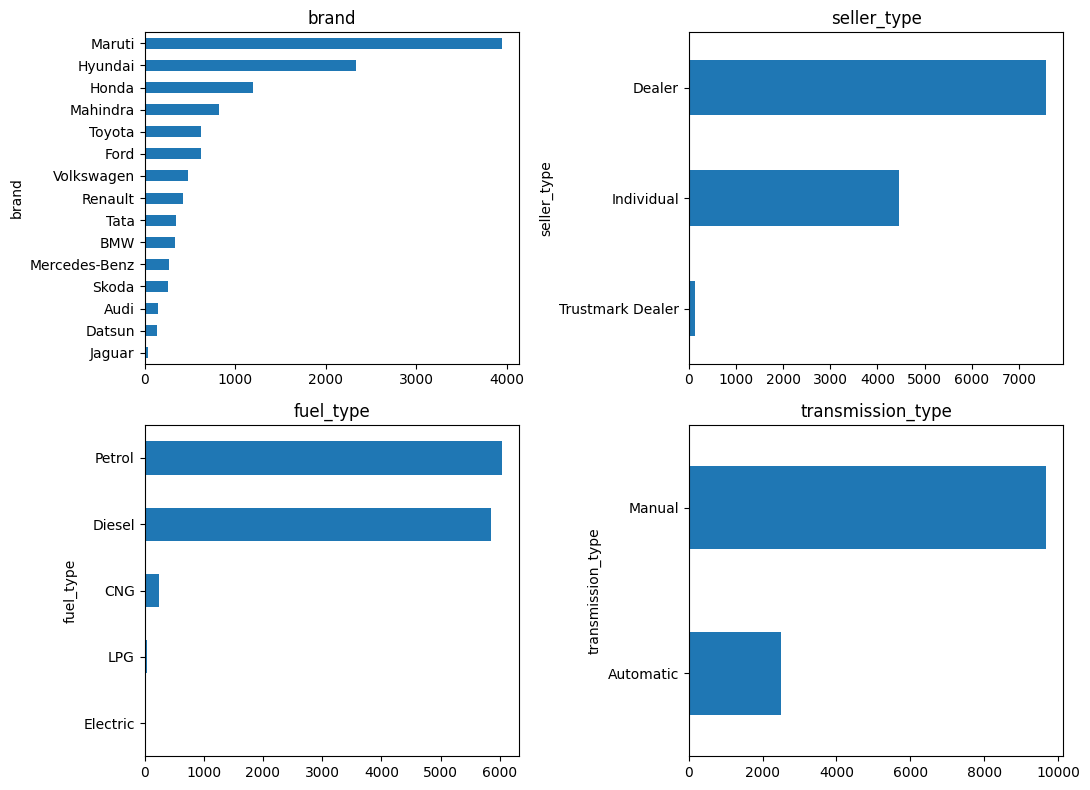

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for column, ax in zip(['brand', 'seller_type', 'fuel_type', 'transmission_type'], axes.flat):
    development[column].value_counts().head(15).sort_values().plot.barh(ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()

In [20]:
development.groupby('fuel_type')['selling_price'].agg(['count', 'median', 'mean'])

Out[0]: 
           count     median          mean
fuel_type                                
CNG          245   370000.0  4.175347e+05
Diesel      5849   700000.0  9.965300e+05
Electric       4  1857500.0  1.853500e+06
LPG           38   195000.0  2.103158e+05
Petrol      6027   460000.0  5.744296e+05


### Relationships and feature selection
Correlation describes linear association, not causation. Power and engine size have strong positive associations with price. Age and fuel economy have negative associations. Weak linear correlation does not rule out useful nonlinear information, so do not automatically remove distance driven.

We use a correlation-based feature-selection experiment for Ridge below: compare the eight highest-scoring encoded inputs with all inputs. Selection happens inside each training fold, not once using the full dataset.

Out[0]: 
mileage         -0.303046
vehicle_age     -0.237470
km_driven       -0.075064
seats            0.115028
engine           0.583973
max_power        0.750220
selling_price    1.000000
Name: selling_price, dtype: float64


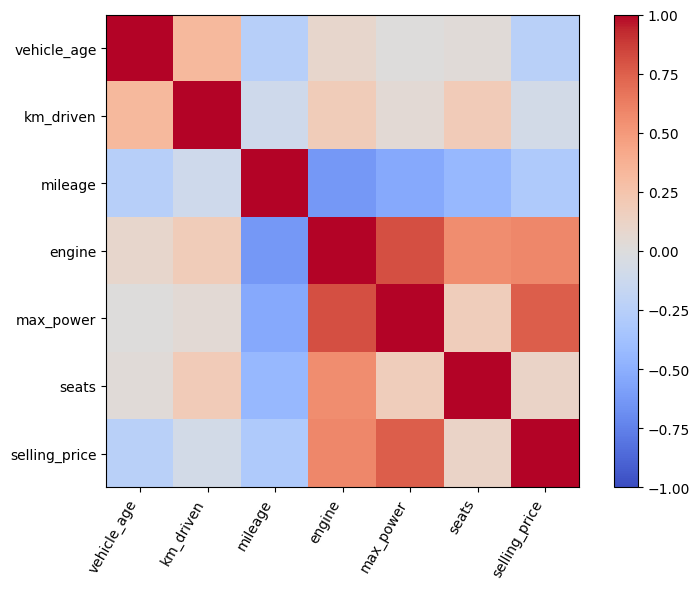

In [21]:
correlation = development[numeric_columns + ['selling_price']].corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=60, ha='right')
ax.set_yticks(range(len(correlation)), correlation.columns)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()
correlation['selling_price'].sort_values()

## 6. Prepare the preprocessing steps
**Pipeline** joins steps so they are fitted and reused in the right order. **ColumnTransformer** sends numerical and categorical columns to the appropriate steps. Defining these objects does not fit them yet.

The categorical pipeline fills missing categories with an explicit label and performs one-hot encoding. This avoids pretending that brand names have a numerical order. Unknown categories will not crash the encoder, but predictions for unfamiliar cars remain uncertain.

In [22]:
category_steps = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Unknown', keep_empty_features=True)),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True))
])

# Ridge benefits from scaling numerical inputs.
ridge_numeric_steps = Pipeline([
    ('impute', SimpleImputer(strategy='median', keep_empty_features=True)),
    ('scale', StandardScaler())
])

# Trees need missing values handled, but do not require scaling.
tree_numeric_steps = Pipeline([
    ('impute', SimpleImputer(strategy='median', keep_empty_features=True))
])

In [23]:
ridge_preprocessing = ColumnTransformer([
    ('numeric', ridge_numeric_steps, numeric_columns),
    ('categories', clone(category_steps), category_columns)
], sparse_threshold=1.0)

tree_preprocessing = ColumnTransformer([
    ('numeric', tree_numeric_steps, numeric_columns),
    ('categories', clone(category_steps), category_columns)
], sparse_threshold=1.0)

clone makes a fresh, unfitted copy for each model. This prevents different models from sharing a fitted encoder accidentally. The sparse output saves memory because most one-hot entries are zero.

## 7. Cross-validation and baseline
GroupKFold uses three development-data folds and keeps identical input profiles together. GridSearchCV tries the listed settings and refits the best setting on the development set. Preprocessing is refitted within every fold.

MAE is our primary selection measure. RMSE and R² provide supporting information. The negative signs in scoring are a scikit-learn convention: larger scores are preferred, so errors are negated. We reverse the signs for reporting.

In [24]:
cv = GroupKFold(n_splits=3)
scoring = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

In [25]:
baseline_pipeline = Pipeline([
    ('preprocess', clone(tree_preprocessing)),
    ('model', DummyRegressor(strategy='median'))
])
baseline_search = GridSearchCV(baseline_pipeline, {}, scoring=scoring,
    refit='MAE', cv=cv, n_jobs=1, error_score='raise')
baseline_search.fit(X_train, y_train, groups=train_groups)
print('Baseline CV MAE:', -baseline_search.best_score_)

Baseline CV MAE: 399809.2458955762


## 8. Model 1 — Ridge regression
Ridge is a regularised linear regression model. It uses scaled numerical inputs and encoded categories. SelectKBest ranks encoded inputs using their individual linear associations with the training target. This is a statistical score, not causal importance.

The outer TransformedTargetRegressor applies log1p to prices during fitting and expm1 to predictions. We therefore evaluate the returned predictions directly in price units. Log-space fitting changes the error emphasis; inverse-log predictions are not automatically unbiased conditional mean prices.

In [26]:
ridge_pipeline = Pipeline([
    ('preprocess', clone(ridge_preprocessing)),
    ('select', SelectKBest(score_func=f_regression)),
    ('model', Ridge(solver='lsqr'))
])
ridge_model = TransformedTargetRegressor(
    regressor=ridge_pipeline, func=np.log1p, inverse_func=np.expm1
)

In [27]:
ridge_parameters = {
    'regressor__model__alpha': [1.0, 10.0],
    'regressor__select__k': [8, 'all']
}
ridge_search = GridSearchCV(ridge_model, ridge_parameters, scoring=scoring,
    refit='MAE', cv=cv, n_jobs=1, error_score='raise')
ridge_search.fit(X_train, y_train, groups=train_groups)
print('Best settings:', ridge_search.best_params_)
print('Ridge CV MAE:', -ridge_search.best_score_)

Best settings: {'regressor__model__alpha': 1.0, 'regressor__select__k': 'all'}
Ridge CV MAE: 115728.0174640775


In [28]:
# Display the actual feature-selection result for the refitted Ridge model.
fitted_ridge = ridge_search.best_estimator_.regressor_
selection = pd.DataFrame({
    'Feature': fitted_ridge.named_steps['preprocess'].get_feature_names_out(),
    'F score': fitted_ridge.named_steps['select'].scores_,
    'Selected': fitted_ridge.named_steps['select'].get_support()
})
print('Selected columns:', selection['Selected'].sum(), 'of', len(selection))
selection.sort_values('F score', ascending=False).head(15)

Selected columns: 166 of 166
Out[0]: 
                                     Feature       F score  Selected
4                         numeric__max_power  16494.443461      True
3                            numeric__engine   9159.266291      True
165     categories__transmission_type_Manual   3898.982708      True
164  categories__transmission_type_Automatic   3898.982708      True
0                       numeric__vehicle_age   3786.158213      True
160             categories__fuel_type_Diesel   2222.793123      True
163             categories__fuel_type_Petrol   1802.857188      True
7                      categories__brand_BMW   1453.470787      True
44                    categories__model_Alto   1332.581418      True
2                           numeric__mileage   1223.040894      True
23                  categories__brand_Maruti   1217.826418      True
26           categories__brand_Mercedes-Benz    962.804463      True
34                  categories__brand_Toyota    800.018234      T

**Selection outcome:** Ridge prefers all encoded features over the top eight. We retain that result rather than forcing feature removal. The forest below uses all justified raw fields; Ridge's selection mask is not silently applied to it.

## 9. Model 2 — Decision tree
A decision tree learns nonlinear splits. Limiting depth and increasing the minimum number of records per leaf can reduce overfitting. Its target remains in ordinary price units.

In [29]:
tree_pipeline = Pipeline([
    ('preprocess', clone(tree_preprocessing)),
    ('model', DecisionTreeRegressor(random_state=42))
])
tree_parameters = {
    'model__max_depth': [8, 16],
    'model__min_samples_leaf': [3, 10]
}

In [30]:
tree_search = GridSearchCV(tree_pipeline, tree_parameters, scoring=scoring,
    refit='MAE', cv=cv, n_jobs=1, error_score='raise')
tree_search.fit(X_train, y_train, groups=train_groups)
print('Best settings:', tree_search.best_params_)
print('Decision tree CV MAE:', -tree_search.best_score_)

Best settings: {'model__max_depth': 16, 'model__min_samples_leaf': 3}
Decision tree CV MAE: 124325.61865806625


## 10. Model 3 — Random forest
The forest averages many trees. We use 120 trees, a fixed seed and one worker to keep the run manageable. We compare two minimum-leaf settings. These are modest experiments, not a claim to have found the globally best possible model.

In [31]:
forest_pipeline = Pipeline([
    ('preprocess', clone(tree_preprocessing)),
    ('model', RandomForestRegressor(n_estimators=120, max_depth=20,
        random_state=42, n_jobs=1))
])
forest_parameters = {'model__min_samples_leaf': [2, 5]}

In [32]:
forest_search = GridSearchCV(forest_pipeline, forest_parameters, scoring=scoring,
    refit='MAE', cv=cv, n_jobs=1, error_score='raise')
forest_search.fit(X_train, y_train, groups=train_groups)
print('Best settings:', forest_search.best_params_)
print('Random forest CV MAE:', -forest_search.best_score_)

Best settings: {'model__min_samples_leaf': 2}
Random forest CV MAE: 105125.6378359314


## 11. Compare models and select one
This small loop only places the four completed searches in a table; it does not hide training. Select the lowest development CV MAE. The test data has not chosen the model or settings. The same CV was used for tuning and comparison, so CV scores are not an independent final performance estimate.

In [33]:
model_names = ['Median baseline', 'Ridge', 'Decision tree', 'Random forest']
searches = [baseline_search, ridge_search, tree_search, forest_search]
comparison_rows = []
for name, search in zip(model_names, searches):
    best = search.best_index_
    comparison_rows.append({
        'Model': name,
        'CV MAE': -search.cv_results_['mean_test_MAE'][best],
        'CV MAE std': search.cv_results_['std_test_MAE'][best],
        'CV RMSE': -search.cv_results_['mean_test_RMSE'][best],
        'CV R2': search.cv_results_['mean_test_R2'][best]
    })
comparison = pd.DataFrame(comparison_rows)
comparison.sort_values('CV MAE')

Out[0]: 
             Model         CV MAE   CV MAE std        CV RMSE     CV R2
3    Random forest  105125.637836  5728.192233  355612.810381  0.845066
1            Ridge  115728.017464  5134.558489  378856.570462  0.825346
2    Decision tree  124325.618658  8376.745767  436254.334398  0.759569
0  Median baseline  399809.245896  8823.223920  931272.983658 -0.059559


In [34]:
best_position = comparison['CV MAE'].idxmin()
best_model_name = comparison.loc[best_position, 'Model']
best_model = searches[best_position].best_estimator_
print('Selected model:', best_model_name)

Selected model: Random forest


## 12. Evaluate the selected model on the test set
Predict once on the reserved test set. **MAE** is the average absolute price error. **RMSE** gives more weight to large misses. **R²** compares squared error with predicting the test-set mean; it is not percentage accuracy. These are regression metrics; classification accuracy, precision, recall and F1 do not apply here.

In [35]:
y_pred = best_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('Test MAE:', round(mae, 2))
print('Test RMSE:', round(rmse, 2))
print('Test R2:', round(r2, 4))

Test MAE: 100519.03
Test RMSE: 221823.84
Test R2: 0.9283


In [36]:
baseline_pred = baseline_search.best_estimator_.predict(X_test)
baseline_mae = mean_absolute_error(y_test, baseline_pred)
training_pred = best_model.predict(X_train)
training_mae = mean_absolute_error(y_train, training_pred)

print('Baseline test MAE:', round(baseline_mae, 2))
print('MAE reduction against baseline (%):', round(100 * (1 - mae / baseline_mae), 2))
print('Training-fit MAE:', round(training_mae, 2))

Baseline test MAE: 403407.7
MAE reduction against baseline (%): 75.08
Training-fit MAE: 58466.44


### Additional error checks
Calculate errors directly so their meaning is visible. The absolute percentage error divides each absolute error by that car's actual price. MAPE is its average; it gives more relative weight to cheaper cars and is problematic near zero. Prices here are positive, but MAPE is still supplementary. Do not call 100 minus MAPE accuracy.

The 10% and 20% thresholds are descriptive examples, not agreed business requirements. The 90th-percentile error is not an individual prediction interval. Signed bias can hide offsetting positive and negative errors.

In [37]:
absolute_errors = np.abs(y_test.to_numpy() - y_pred)
percentage_errors = 100 * absolute_errors / y_test.to_numpy()
median_error = np.median(absolute_errors)
median_percentage_error = np.median(percentage_errors)
within_10 = 100 * np.mean(percentage_errors <= 10)
within_20 = 100 * np.mean(percentage_errors <= 20)

print('Median absolute error:', round(median_error, 2))
print('Mean absolute percentage error:', round(percentage_errors.mean(), 2), '%')
print('Median absolute percentage error:', round(median_percentage_error, 2), '%')
print('Within 10% of actual price:', round(within_10, 2), '%')
print('Within 20% of actual price:', round(within_20, 2), '%')
print('90th percentile absolute error:', round(np.quantile(absolute_errors, .9), 2))
print('Mean prediction minus actual:', round(np.mean(y_pred - y_test), 2))

Median absolute error: 53947.72
Mean absolute percentage error: 13.33 %
Median absolute percentage error: 10.08 %
Within 10% of actual price: 49.89 %
Within 20% of actual price: 80.01 %
90th percentile absolute error: 199937.26
Mean prediction minus actual: -4368.2


In [38]:
results = X_test.copy()
results['Actual price'] = y_test
results['Predicted price'] = y_pred
results['Absolute error'] = absolute_errors
results['Percentage error'] = percentage_errors
results.head(10)

Out[0]: 
    vehicle_age  km_driven  ...  Absolute error  Percentage error
3           9.0    37000.0  ...     9700.899471          4.292433
4           6.0    30000.0  ...    64862.602979         11.379404
9           4.0    28321.0  ...    20186.276245          3.950348
15          7.0    65000.0  ...    49182.073413          3.451374
27         14.0    77253.0  ...    48424.236111         33.396025
32         12.0    80000.0  ...    11563.194444          9.250556
33          9.0   185000.0  ...    39884.325397          6.647388
38          7.0    56000.0  ...    58327.269797         14.226163
43          5.0    54000.0  ...   110962.230802         18.493705
44          2.0    10000.0  ...    14447.261003          3.246576

[10 rows x 15 columns]


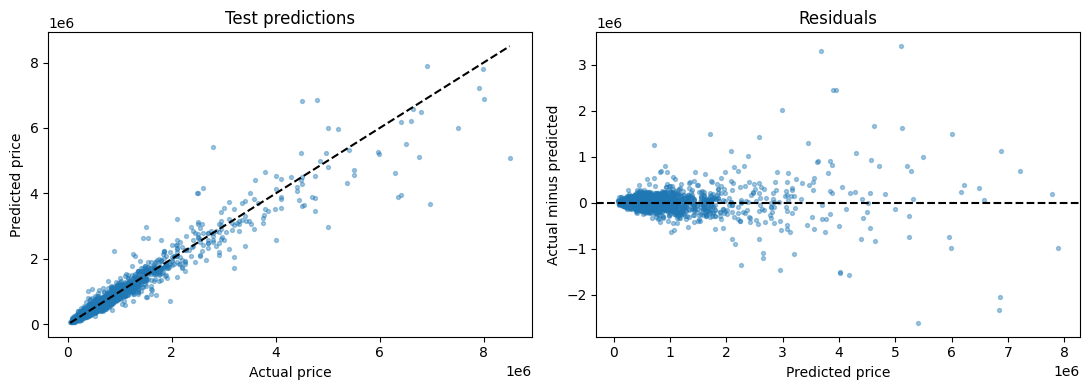

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred, s=8, alpha=.4)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
axes[0].plot([low, high], [low, high], 'k--')
axes[0].set(xlabel='Actual price', ylabel='Predicted price', title='Test predictions')
axes[1].scatter(y_pred, y_test - y_pred, s=8, alpha=.4)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Predicted price', ylabel='Actual minus predicted', title='Residuals')
plt.tight_layout()
plt.show()

Check performance for different groups. A small group is weaker evidence than a large group. Define price bands from the development-price quartiles, then describe test errors within those bands. These checks do not change the model.

In [40]:
results.groupby('brand').agg(
    Count=('Actual price', 'size'),
    MAE=('Absolute error', 'mean'),
    Mean_percentage_error=('Percentage error', 'mean')
).sort_values('MAE', ascending=False)

Out[0]: 
               Count           MAE  Mean_percentage_error
brand                                                    
Lexus              2  1.764843e+06              29.170014
Land Rover        13  1.173297e+06              25.941649
Porsche            4  8.324347e+05              15.597903
Volvo              5  7.817279e+05              17.811647
Jaguar            20  6.075643e+05              25.749393
BMW              102  4.010376e+05              16.970947
Mini               1  3.912865e+05              20.868616
Audi              42  3.359110e+05              14.678521
Mercedes-Benz     60  3.114827e+05              15.467590
Nissan             2  2.976322e+05              26.886934
MG                 6  1.893162e+05              11.605373
Kia                9  1.485913e+05               8.384661
Skoda             70  1.471784e+05              22.466102
Toyota           163  1.404244e+05              12.121570
Mahindra         177  1.003981e+05              15.633361
Tata 

In [41]:
price_boundaries = np.unique(np.r_[-np.inf, y_train.quantile([.25, .5, .75]), np.inf])
results['Price band'] = pd.cut(results['Actual price'], price_boundaries)
results.groupby('Price band', observed=True).agg(
    Count=('Actual price', 'size'),
    MAE=('Absolute error', 'mean'),
    Mean_percentage_error=('Percentage error', 'mean')
)

Out[0]: 
                      Count            MAE  Mean_percentage_error
Price band                                                       
(-inf, 380000.0]        746   44367.907854              17.986137
(380000.0, 555000.0]    776   56832.106377              12.269358
(555000.0, 825000.0]    823   72070.197491              10.740886
(825000.0, inf]         736  235305.940109              12.642269


### Optional interpretation: permutation importance
Shuffle one input field at a time and measure how much worse the frozen model predicts. Use the same 1,000-row sample for both baseline and shuffled scores. This is descriptive; correlated features can share importance. It does not show causation and we do not use the test-set ranking to redesign the model.

In [42]:
importance_sample = X_test.sample(n=min(1000, len(X_test)), random_state=42)
importance = permutation_importance(
    best_model, importance_sample, y_test.loc[importance_sample.index],
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=42, n_jobs=1
)
pd.DataFrame({
    'Feature': feature_columns,
    'Increase in MAE': importance.importances_mean,
    'Repeat std': importance.importances_std
}).sort_values('Increase in MAE', ascending=False)

Out[0]: 
              Feature  Increase in MAE    Repeat std
4           max_power    347683.245342  18620.433118
0         vehicle_age    190971.688255   5087.636770
3              engine     61906.157881   1080.476817
1           km_driven     19844.206013   2920.168931
7               model     13721.867032    767.740955
2             mileage     10536.895428   1372.917600
10  transmission_type      5018.303585    999.659842
9           fuel_type      3622.345909    688.843484
6               brand      3319.337077    743.192401
8         seller_type      1811.497073    441.213022
5               seats       947.649496    174.419363


## 13. Conclusions
The random forest wins by development CV MAE (about 105,126). Its test MAE is about 100,519, RMSE 221,824 and R² 0.9283. It reduces MAE by about 75.1% against the median baseline. Training-fit MAE is 58,466, showing some overfitting. Average CV R² is about 0.845, lower than the test R²; price distribution and extreme cars affect this measure. Report both rather than cherry-picking R².

Median absolute error is 53,948 price units. Median percentage error is 10.08%; approximately 49.89% of estimates are within 10% and 80.01% within 20%. The cheapest band has mean percentage error about 18%, while expensive cars have larger absolute errors. These results are useful for a PGDip portfolio, but do not establish a commercially reliable valuation service.

Ridge selected all encoded columns rather than only eight. The forest retained all eleven justified raw inputs. We did not force feature removal or transform every skewed input.

Limitations: currency, source/licence, units and dates remain unconfirmed; extreme distances need checking; condition/location/service history are absent; no time-based or external-market validation is available. Grouped splitting reduces identical-input overlap but cannot identify all repeat listings. Further model changes should be evaluated in development CV, not by chasing this already inspected holdout. A new dataset would be needed for renewed independent claims. The formal report, slides and recorded presentation are separate assignment requirements.

## 14. Save the pipeline for the app
Save the entire fitted pipeline so the app uses the same imputation and encoding. The dictionary below is simply a labelled container: pipeline plus the category menus, defaults and evaluation figures the app needs. It is not another modelling step.

We save the same development-fitted model evaluated above. We do not quietly refit using the test set. The next two cells overwrite car_price_pipeline.joblib in this folder.

In [43]:
# Build the app's menus and numerical defaults from development data only.
category_choices = {}
for column in category_columns:
    category_choices[column] = sorted(X_train[column].dropna().unique().tolist())

brand_models = {}
for brand, cars in X_train.groupby('brand'):
    brand_models[brand] = sorted(cars['model'].dropna().unique().tolist())

numeric_ranges = {}
for column in numeric_columns:
    numeric_ranges[column] = {
        'min': float(X_train[column].min()),
        'max': float(X_train[column].max()),
        'median': float(X_train[column].median())
    }

In [44]:
metadata = {
    'source': 'Unconfirmed',
    'currency': 'Unconfirmed dataset currency',
    'quick_software_test': False,
    'categories': category_choices,
    'brand_models': brand_models,
    'numeric_ranges': numeric_ranges,
    'evaluation': {
        'selected_model': best_model_name,
        'holdout': {'MAE': mae, 'RMSE': rmse, 'R2': r2,
                    'median_APE_pct': median_percentage_error,
                    'within_10pct': within_10, 'within_20pct': within_20}
    }
}
joblib.dump({'pipeline': best_model, 'metadata': metadata},
            'car_price_pipeline.joblib', compress=3)
print('Saved pipeline for Streamlit.')

Saved pipeline for Streamlit.


## 15. Open the application
In **VS Code → Terminal → PowerShell**, from this project folder:
```powershell
.\.venv\Scripts\python.exe -m streamlit run app.py
```
Streamlit prints a local browser address. The app needs only its code and the saved pipeline for predictions. It does not need an active notebook session. Use the README for installation and starting a new GitHub repository. No public deployment is claimed.